# Домашнее задание: матрица и затухающий осциллятор

## Часть 1. Класс Matrix

In [2]:
class Matrix:
    # Matrix(data=[[1, 2], [3, 4]])  - матрица из списка списков
    # Matrix(rows=2, cols=3)         - нулевая матрица 2 на 3
    def __init__(self, data=None, rows=0, cols=0):
        if data is not None:
            self.data = []
            for row in data:
                self.data.append(list(row))
            self.rows = len(data)
            self.cols = len(data[0])
        else:
            self.data = []
            for i in range(rows):
                self.data.append([0] * cols)
            self.rows = rows
            self.cols = cols

    # показать матрицу на экране
    def show(self):
        for row in self.data:
            print(row)

    # получить элемент [i][j]
    def get(self, i, j):
        return self.data[i][j]

    # замена элемента [i][j] на value
    def set(self, i, j, value):
        self.data[i][j] = value

    # сложение матриц
    def add(self, other):
        result = Matrix(rows=self.rows, cols=self.cols)
        for i in range(self.rows):
            for j in range(self.cols):
                result.data[i][j] = self.data[i][j] + other.data[i][j]
        return result

    # альтернативный способ сложения матриц через оператор +
    def __add__(self, other):
        result = Matrix(rows=self.rows, cols=self.cols)
        for i in range(self.rows):
            for j in range(self.cols):
                result.data[i][j] = self.data[i][j] + other.data[i][j]
        return result

    # умножение на число
    def mul_number(self, number):
        result = Matrix(rows=self.rows, cols=self.cols)
        for i in range(self.rows):
            for j in range(self.cols):
                result.data[i][j] = self.data[i][j] * number
        return result

    # умножение матриц
    def mul_matrix(self, other):
        result = Matrix(rows=self.rows, cols=other.cols)
        for i in range(self.rows):
            for j in range(other.cols):
                s = 0
                for k in range(self.cols):
                    s += self.data[i][k] * other.data[k][j]
                result.data[i][j] = s
        return result

    # альтернативный способ умножения матриц через оператор *
    def __mul__(self, other):
        if isinstance(other, (int, float)):
            return self.mul_number(other)
        elif isinstance(other, Matrix):
            return self.mul_matrix(other)
        else:
            raise ValueError("Error multiplication!")

    # матрица без строки 0 и без столбца j (для определителя)
    def minor(self, j):
        rows = []
        for i in range(1, self.rows):
            row = []
            for col in range(self.cols):
                if col != j:
                    row.append(self.data[i][col])
            rows.append(row)
        return Matrix(data=rows)

    # определитель: разложение по первой строке
    def det(self):
        if self.rows == 1:
            return self.data[0][0]
        result = 0
        for j in range(self.cols):
            sign = (-1) ** j
            result += sign * self.data[0][j] * self.minor(j).det()
        return result

### Проверка матрицы

In [6]:
A = Matrix(data=[[1, 2], [3, 4]])
B = Matrix(data=[[0, 1], [1, 0]])
Z = Matrix(rows=2, cols=3)

print("Нулевая матрица:"); Z.show()
print("A:");               A.show()
print("A[1][0] =", A.get(1, 0))
print("A + B:");           (A+B).show()
print("A * 2.5:");         (A * 2.5).show()
print("A * B:");           (A * B).show()
print("det A =", A.det())

D = Matrix(data=[[2, 0, 1], [1, 3, 2], [1, 1, 1]])
print("det D =", D.det(), "(должно быть 2*(3-2) - 0 + 1*(1-3) = 0)")

import numpy as np                       # сверка с numpy
X = np.random.randint(-5, 6, size=(4, 4))
print(Matrix(data=X.tolist()).det(), np.linalg.det(X))

Нулевая матрица:
[0, 0, 0]
[0, 0, 0]
A:
[1, 2]
[3, 4]
A[1][0] = 3
A + B:
[1, 3]
[4, 4]
A * 2.5:
[2.5, 5.0]
[7.5, 10.0]
A * B:
[2, 1]
[4, 3]
det A = -2
det D = 0 (должно быть 2*(3-2) - 0 + 1*(1-3) = 0)
318 318.0


## Часть 2. Осциллятор

Уравнение: $a = -\dfrac{k}{m}x - 2\delta v$, энергия $E = \dfrac{mv^2}{2} + \dfrac{kx^2}{2}$.

В методе `step` два способа сделать шаг:
* `"simple"` — как в примере с занятия;
* `"better"` — сначала обновляем скорость, потом положение по новой скорости. Почти так же просто, но энергия не уезжает.

In [7]:
class Oscillator:
    def __init__(self, m, k, delta, x, v):
        self.m = m
        self.k = k
        self.delta = delta
        self.x = x
        self.v = v
        self.t = 0.0

    def acceleration(self):
        return -self.k / self.m * self.x - 2 * self.delta * self.v

    def energy(self):
        return self.m * self.v ** 2 / 2 + self.k * self.x ** 2 / 2

    def step(self, dt, method="better"):
        a = self.acceleration()
        if method == "simple":
            self.x = self.x + self.v * dt + a * dt ** 2 / 2
            self.v = self.v + a * dt
        else:
            self.v = self.v + a * dt
            self.x = self.x + self.v * dt
        self.t = self.t + dt

### Файл с параметрами `params.txt` (строки вида `имя = значение`)

In [13]:
text = """m = 1.0
k = 4.0
delta = 0.2
x0 = 1.0
v0 = 0.0
T = 20.0
dt = 0.001
method = better
"""
with open("params.txt", "w") as f:
    f.write(text)

In [14]:
import matplotlib.pyplot as plt


class Simulator:
    def __init__(self, filename):
        self.read_params(filename)
        self.osc = Oscillator(self.m, self.k, self.delta, self.x0, self.v0)

    def read_params(self, filename):
        params = {}
        with open(filename) as f:
            for line in f:
                line = line.strip()
                if line == "":
                    continue
                name, value = line.split("=")
                params[name.strip()] = value.strip()
        self.m = float(params["m"])
        self.k = float(params["k"])
        self.delta = float(params["delta"])
        self.x0 = float(params["x0"])
        self.v0 = float(params["v0"])
        self.T = float(params["T"])
        self.dt = float(params["dt"])
        self.method = params["method"]

    def simulate(self):
        self.t_list = [self.osc.t]
        self.x_list = [self.osc.x]
        self.v_list = [self.osc.v]
        self.E_list = [self.osc.energy()]
        steps = int(self.T / self.dt)
        for i in range(steps):
            self.osc.step(self.dt, self.method)
            self.t_list.append(self.osc.t)
            self.x_list.append(self.osc.x)
            self.v_list.append(self.osc.v)
            self.E_list.append(self.osc.energy())

    def plot(self):
        plt.figure(figsize=(12, 8))

        plt.subplot(2, 2, 1)
        plt.plot(self.t_list, self.x_list)
        plt.title("x(t)"); plt.xlabel("t, с"); plt.ylabel("x, м"); plt.grid(True)

        plt.subplot(2, 2, 2)
        plt.plot(self.t_list, self.v_list)
        plt.title("v(t)"); plt.xlabel("t, с"); plt.ylabel("v, м/с"); plt.grid(True)

        plt.subplot(2, 2, 3)
        plt.plot(self.t_list, self.E_list)
        plt.title("E(t)"); plt.xlabel("t, с"); plt.ylabel("E, Дж"); plt.grid(True)

        plt.subplot(2, 2, 4)
        plt.plot(self.x_list, self.v_list)
        plt.title("Фазовая диаграмма"); plt.xlabel("x"); plt.ylabel("v"); plt.grid(True)

        plt.tight_layout()
        plt.show()

Matplotlib is building the font cache; this may take a moment.


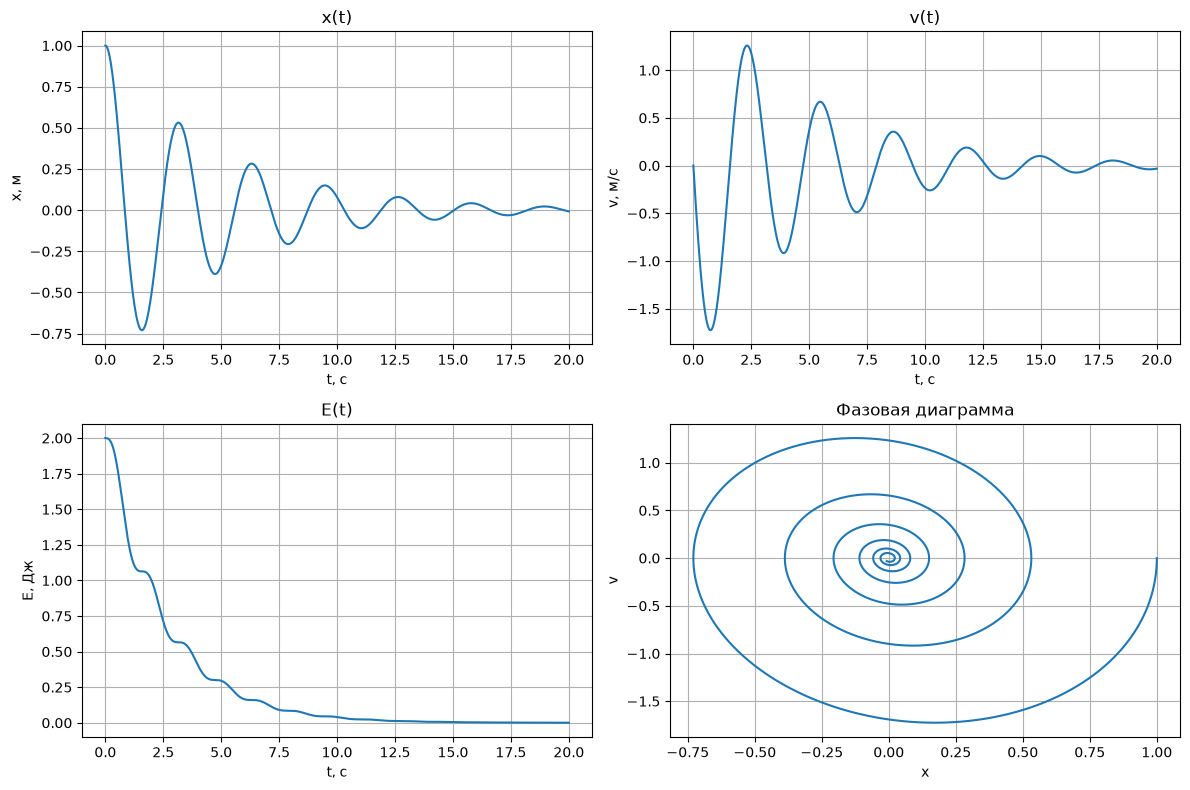

In [15]:
sim = Simulator("params.txt")
sim.simulate()
sim.plot()

## Часть 3. Проверка и исследование

### Без затухания энергия должна сохраняться

simple : E в начале = 2.0 , в конце = 2.0827
better : E в начале = 2.0 , в конце = 2.002


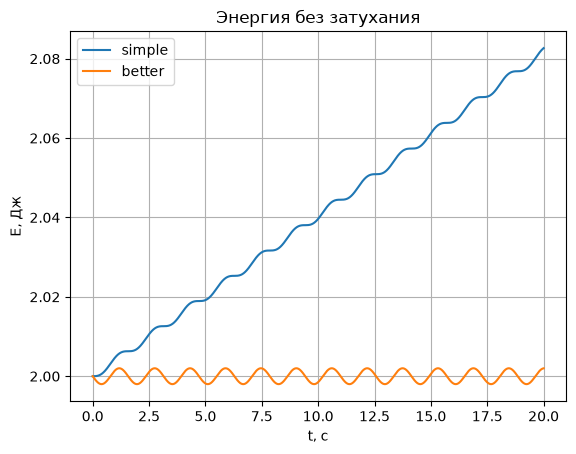

In [16]:
def run(delta, method, dt=0.001, T=20.0, x0=1.0, v0=0.0, m=1.0, k=4.0):
    osc = Oscillator(m, k, delta, x0, v0)
    t_list, x_list, E_list = [0.0], [x0], [osc.energy()]
    for i in range(int(T / dt)):
        osc.step(dt, method)
        t_list.append(osc.t); x_list.append(osc.x); E_list.append(osc.energy())
    return np.array(t_list), np.array(x_list), np.array(E_list)

for method in ["simple", "better"]:
    t, x, E = run(0.0, method)
    plt.plot(t, E, label=method)
    print(method, ": E в начале =", E[0], ", в конце =", round(E[-1], 4))
plt.title("Энергия без затухания"); plt.xlabel("t, с"); plt.ylabel("E, Дж")
plt.legend(); plt.grid(True); plt.show()

Способ `"simple"` (как на занятии) заставляет энергию медленно расти, а `"better"` держит её почти постоянной.

### Сравнение с теорией

Слабое затухание ($\delta < \omega_0$, где $\omega_0=\sqrt{k/m}$):
$x(t)=e^{-\delta t}\left(x_0\cos\omega t+\dfrac{v_0+\delta x_0}{\omega}\sin\omega t\right)$, $\omega=\sqrt{\omega_0^2-\delta^2}$.
Критическое ($\delta=\omega_0$): $x=e^{-\delta t}(x_0+(v_0+\delta x_0)t)$.
Сильное ($\delta>\omega_0$): $x=e^{-\delta t}\left(x_0\cosh\Omega t+\dfrac{v_0+\delta x_0}{\Omega}\sinh\Omega t\right)$, $\Omega=\sqrt{\delta^2-\omega_0^2}$.

In [ ]:
def x_theory(t, delta, x0=1.0, v0=0.0, m=1.0, k=4.0):
    w0 = np.sqrt(k / m)
    c = v0 + delta * x0
    if delta < w0:
        w = np.sqrt(w0 ** 2 - delta ** 2)
        return np.exp(-delta * t) * (x0 * np.cos(w * t) + c / w * np.sin(w * t))
    elif delta == w0:
        return np.exp(-delta * t) * (x0 + c * t)
    else:
        W = np.sqrt(delta ** 2 - w0 ** 2)
        return np.exp(-delta * t) * (x0 * np.cosh(W * t) + c / W * np.sinh(W * t))

plt.figure(figsize=(14, 7))
cases = [(0.0, "без затухания"), (0.2, "слабое"), (2.0, "критическое"), (4.0, "сильное")]
for n, (delta, name) in enumerate(cases):
    t, x, E = run(delta, "better", T=10.0)
    xt = x_theory(t, delta)
    print(name, ": максимальная разница с теорией =", round(np.max(np.abs(x - xt)), 5))
    plt.subplot(2, 2, n + 1)
    plt.plot(t, x, label="симуляция")
    plt.plot(t, xt, "--", label="теория")
    plt.title(name + " (delta = " + str(delta) + ")"); plt.xlabel("t, с"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

### Выводы

* Без затухания: колебания с периодом $2\pi\sqrt{m/k}$, энергия постоянна, на фазовой диаграмме эллипс.
* Слабое затухание: колебания внутри огибающей $e^{-\delta t}$, фазовая диаграмма: спираль к нулю.
* Критическое: самое быстрое возвращение к нулю без колебаний.
* Сильное: медленное возвращение к нулю без колебаний.
* Симуляция совпадает с аналитическим решением во всех случаях.